# Data Prep

**Question:** What are we predicting, how was the data cleaned, and how much does the cleanup matter?

We predict a song's genre (one of 5) from its 14 Spotify audio features. Every cleaning step lives in `0_foundation.ipynb`; this notebook measures what each step is worth.

In [1]:
import sys; sys.path.insert(0, "../..")
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from common import load, logistic_regression, random_forest, FEATURES

d = load()                                # the cleaned, frozen songs
raw = pd.read_csv("../../dataset.csv")    # the original 114,000 tracks

## 1. The cleaning funnel

How many rows survive each step. The sub-genre to parent-genre mapping is read back from the cleaned table (65 sub-genres kept, 5 parents).

Raw Spotify tracks    114000
In our 5 genres        65000
One genre per song     57793
Unique track IDs       49737
No re-releases         45046
dtype: int64

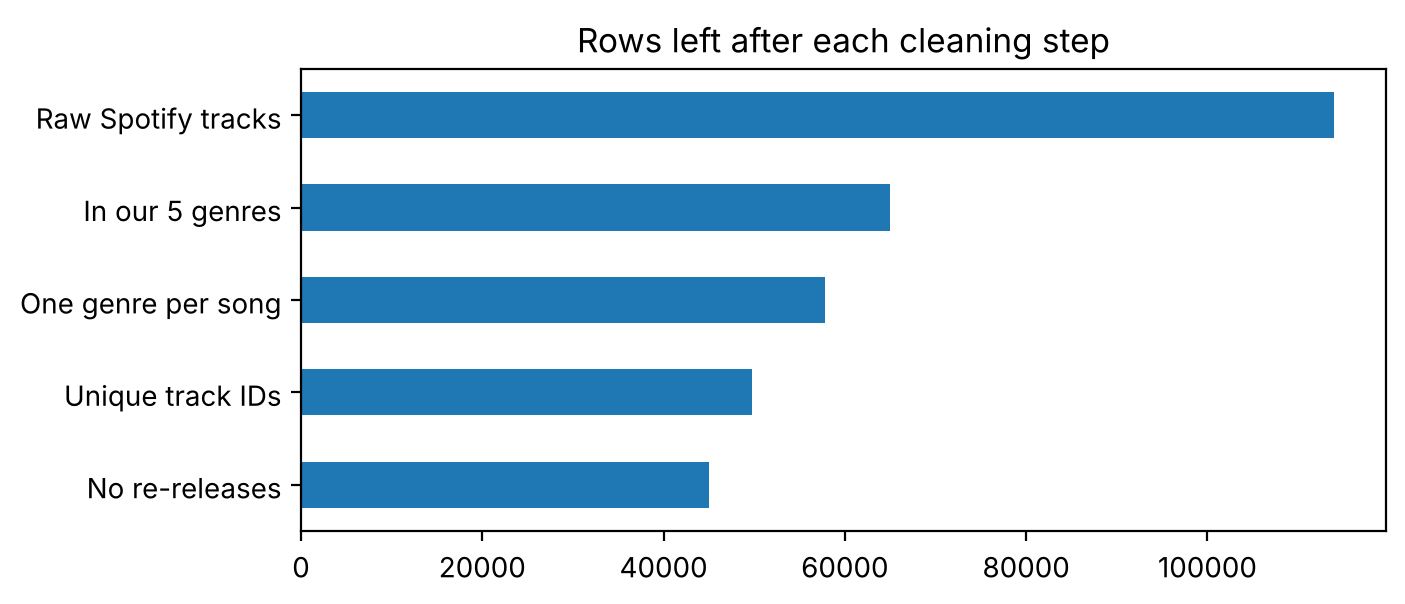

In [2]:
genre_map = dict(zip(d.songs["track_genre"], d.songs["broad_genre"]))

steps = {"Raw Spotify tracks": len(raw)}
df = raw.assign(broad_genre=raw["track_genre"].map(genre_map)).dropna(subset=["broad_genre"])
steps["In our 5 genres"] = len(df)

song = df["artists"].astype(str).str.lower() + " | " + df["track_name"].astype(str).str.lower()
two_genres = (df.groupby("track_id")["broad_genre"].transform("nunique") > 1) | (df.groupby(song)["broad_genre"].transform("nunique") > 1)
df = df[~two_genres]
steps["One genre per song"] = len(df)

df = df.drop_duplicates("track_id")
steps["Unique track IDs"] = len(df)
df = df.drop_duplicates(["artists", "track_name"])
steps["No re-releases"] = len(df)

assert len(df) == len(d.songs)
funnel = pd.Series(steps)
funnel.iloc[::-1].plot.barh(title="Rows left after each cleaning step", figsize=(7, 3))
funnel

## 2. The honesty ladder

The same two models, scored three ways, from least to most honest:

1. **Leaky:** duplicates kept and a random 80/20 split of the 65,000 rows, so copies of a song can sit on both sides.
2. **Official:** our frozen split (duplicates removed, split by artist). These are the saved test predictions everyone uses.
3. **Artists never seen:** only the test songs where none of the credited artists (including collaborators) appear anywhere in training.

3937 of 9009 test songs have artists the models never saw


,Leaky split,Official split,Artists never seen
logistic_regression,52.6,57.0,55.2
random_forest,70.5,64.0,60.6


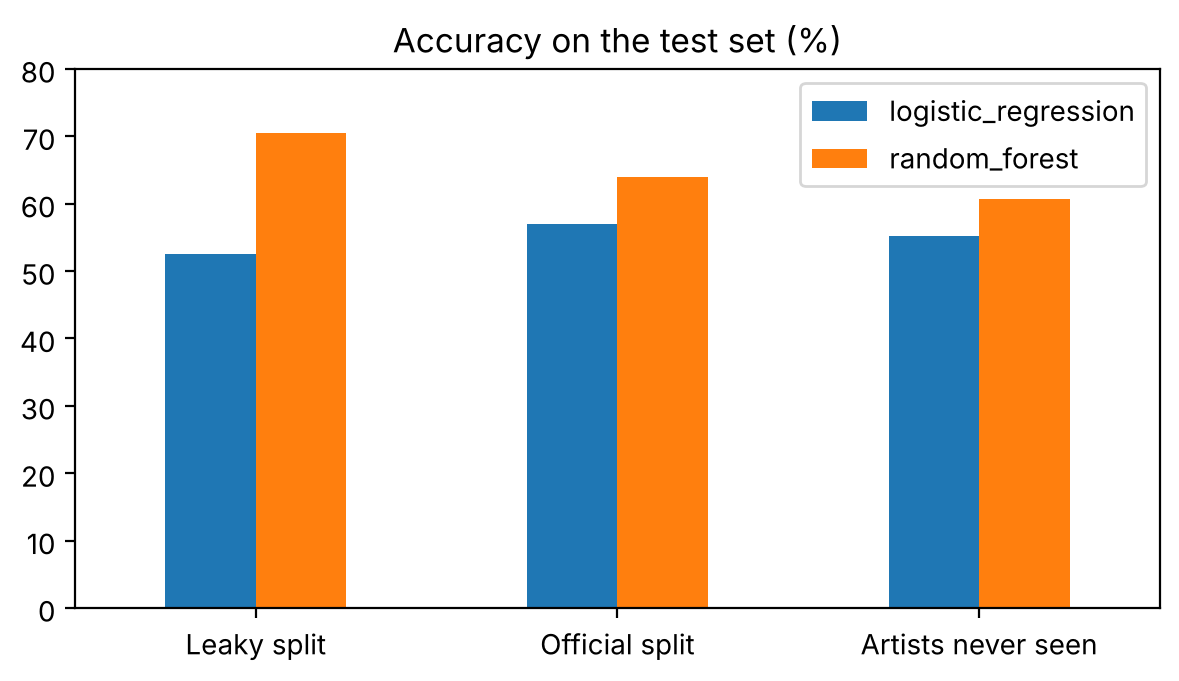

In [3]:
leaky = raw.assign(broad_genre=raw["track_genre"].map(genre_map)).dropna(subset=["broad_genre"])
X_tr, X_te, y_tr, y_te = train_test_split(leaky[FEATURES], leaky["broad_genre"], test_size=0.2,
                                          random_state=42, stratify=leaky["broad_genre"])

artists = d.songs["artists"].fillna("").str.split(";")
train_artists = {a.strip() for names in artists[d.songs["split"] == "train"] for a in names if a.strip()}
test = d.songs[d.songs["split"] == "test"]
never_seen = artists[d.songs["split"] == "test"].apply(lambda names: not any(a.strip() in train_artists for a in names if a.strip()))

ladder = {}
for name, make_model in {"logistic_regression": logistic_regression, "random_forest": random_forest}.items():
    leaky_acc = (make_model().fit(X_tr, y_tr).predict(X_te) == y_te).mean()
    preds = pd.read_csv(f"../../predictions/{name}.csv").set_index("track_id").loc[test["track_id"]]
    correct = preds["predicted"].values == test["broad_genre"].values
    ladder[name] = {"Leaky split": leaky_acc, "Official split": correct.mean(), "Artists never seen": correct[never_seen.values].mean()}

ladder = pd.DataFrame(ladder).T
(ladder * 100).T.plot.bar(rot=0, title="Accuracy on the test set (%)", figsize=(7, 3.5), ylim=(0, 80))
print(f"{never_seen.sum()} of {len(test)} test songs have artists the models never saw")
(ladder * 100).round(1)

### Why doesn't the leak flatter logistic regression?

The leaky data mixes two problems: duplicate songs (which let a model memorize) and songs tagged under two genres (conflicting labels). Removing only the two-genre songs separates them.

In [4]:
clean_labels = leaky[~two_genres]   # same rows as the 65,000-row frame used in the funnel
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(clean_labels[FEATURES], clean_labels["broad_genre"], test_size=0.2,
                                              random_state=42, stratify=clean_labels["broad_genre"])
for name, make_model in {"logistic_regression": logistic_regression, "random_forest": random_forest}.items():
    acc = (make_model().fit(X_tr2, y_tr2).predict(X_te2) == y_te2).mean()
    print(f"{name:20s} duplicates kept, two-genre songs removed: {acc:.1%}   official: {ladder.loc[name, 'Official split']:.1%}")

logistic_regression  duplicates kept, two-genre songs removed: 55.7%   official: 57.0%


random_forest        duplicates kept, two-genre songs removed: 74.0%   official: 64.0%


## 3. The collaboration gap

The split grouped songs by the exact `artists` text, so "A" and "A;B" counted as different artists. That keeps the same name out of both sides, but collaborators can still cross over.

In [5]:
seen_share = 1 - never_seen.mean()
print(f"Test songs sharing at least one artist with training: {(~never_seen).sum()} of {len(test)} ({seen_share:.1%})")
print(f"Songs credited to more than one artist: {d.songs['artists'].fillna('').str.contains(';').mean():.1%}")
gap = ladder["Official split"] - ladder["Artists never seen"]
print("Accuracy boost from familiar artists (points):", (gap * 100).round(1).to_dict())

Test songs sharing at least one artist with training: 5072 of 9009 (56.3%)
Songs credited to more than one artist: 24.8%
Accuracy boost from familiar artists (points): {'logistic_regression': 1.7, 'random_forest': 3.4}


## Takeaways

- Cleaning took us from 114,000 rows to 45,046 unique songs, one genre each.
- **The leak only fools the complex model.** With duplicates kept and a random split, the forest scores 70.5% against its honest 64.0% (74.0% once the two-genre songs are removed), because copies of a song sit on both sides and it can memorize them. Logistic regression can't memorize, so it gets no boost; the conflicting two-genre labels just drag it down to 52.6%.
- **The collaboration gap:** over half the test songs share a collaborating artist with training. Both models do better on those songs and the forest gains about twice as much, so part of its lead comes from recognizing artists. On artists neither model has seen, the forest's lead shrinks from 7.0 to 5.4 points. We kept the frozen split so everyone's numbers stay the same, and report this as a limitation.